# hiNiche: Simulated colorectal cancer TME (simulation benchmark)

Multi-scale (spot / cell / niche) cell-type deconvolution and niche discovery on spatial transcriptomics data simulated from a colorectal cancer tumor microenvironment (TME) reference.
The simulated AnnData provides the ground truth used for evaluation:

- `obsm["S_s2c"]`: spot-to-cell assignment
- `obs["celltype"]`: ground-truth cell type of each spot
- `obs["niche_id"]`: ground-truth niche of each spot

## 1. Setup and imports

In [1]:
import os
import sys
# cupy (used by rapids_singlecell) compiles GPU kernels at runtime and needs the CUDA headers shipped inside the conda environment
os.environ.setdefault("CUDA_PATH", os.path.join(sys.prefix, "targets", "x86_64-linux"))

# --- Project modules ---
import config
import utils
from train import run_train_seq

# --- Standard library ---
import warnings

# --- Data handling ---
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import scipy.sparse as sp

# --- Deep learning ---
import torch
import torch.nn.functional as F

# --- Clustering and evaluation ---
import rapids_singlecell as rsc     # GPU-accelerated neighbors / UMAP
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import normalized_mutual_info_score as NMI, adjusted_rand_score as ARI

# --- Plotting ---
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

/hpc/home/wz220/miniconda3/envs/hiNiche/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Parameter configuration

In [2]:
SAMPLE = "Simulation1_HD"

# Data paths
h5_path     = f"DATA/{SAMPLE}/sim_TME.h5ad"
refile_path = f"DATA/{SAMPLE}/lambda_matrix.csv"

# Patch save path
PATCH_LOC = f"DATA/{SAMPLE}/mini_batch_cache"

# Model save path (an existing checkpoint is loaded instead of retraining)
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint.pt"

# Color maps defined in config.py
celltype_color = getattr(config, "colormap_coloncatlas_18")
umap_color     = getattr(config, "umap_40")

# Model / training hyperparameters
graph_knn   = 12
niche_knn   = 20
lr          = 0.005
num_epochs  = 500
edge_drop   = 0.5
member_drop = 0.5
neg_samples = 5
tau         = 1
alpha       = 1
beta        = 1
seed        = 42
device      = "cuda:0"

# Niche clustering
n_clusters = 5    # number of KMeans clusters (= number of simulated niches)
emb_k      = 50   # n_neighbors of the kNN graph used for UMAP only

## 3. Data loading and preprocessing

### 3.1 Load simulated data and reference

In [3]:
# Reference expression profiles (genes x cell types) and simulated spot-level counts
ref_df = pd.read_csv(refile_path, index_col=0)
adata = sc.read(h5_path)
print(adata)

AnnData object with n_obs × n_vars = 360000 × 6008
    obs: 'spotid', 'celltype', 'x', 'y', 'cell_id', 'niche_id', 'niche_name'
    uns: 'cells', 'celltype_names', 'niche_compositions', 'niche_names', 'pattern', 'spatial_neighbors'
    obsm: 'S_s2c', 'spatial_grid'
    layers: 'counts_clean'
    obsp: 'spatial_connectivities', 'spatial_distances'


### 3.2 Normalization

In [4]:
# Keep raw counts before normalization
adata.layers["counts"] = adata.X.copy()
adata.var_names_make_unique()

# Library-size normalization + log transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

### 3.3 Align genes with the reference

In [5]:
# Restrict to genes shared between the data and the reference
overlap_gs = adata.var.index.intersection(ref_df.index)
print(f"[Log] num of gene overlap {len(overlap_gs)}")

adata.obsm["X_mle"] = adata.layers["counts"][:, adata.var_names.isin(overlap_gs)]   # raw counts
adata.obsm["X_input"] = adata[:, adata.var_names.isin(overlap_gs)].X                # normalized model input

print(f"[Log] input gene number is {len(overlap_gs)}")
ref_matrix = ref_df.loc[overlap_gs].values
ref_matrix = np.array(ref_matrix)

celltypes = list(ref_df.columns)
print(f"[Log] rna ref size is {ref_matrix.shape}")

[Log] num of gene overlap 6008
[Log] input gene number is 6008
[Log] rna ref size is (6008, 18)


## 4. Build the spot / cell / niche hierarchy

### 4.1 Spot-to-cell and spot-to-niche assignment

In [6]:
# Spot -> cell assignment taken from the simulation (ground-truth cell segmentation)
S_s2c_all, cell_background_mask = utils.spot2cell_from_assignment(adata.obsm["S_s2c"], max_spots_per_cell=200, min_spots_per_cell=1)
print(f"[Log] {S_s2c_all.shape[1]} cells are detected")

# Spot -> niche assignment: each niche is a cell plus its nearest neighbors (including itself)
S_s2n_all, niche_background_mask, active_niche_indices, S_c2n_all = utils.spot2niche_by_cell_knn(adata.obsm["spatial_grid"], S_s2c_all, k_niche=niche_knn)
background_mask = {"cell": cell_background_mask, "niche": niche_background_mask}

[Log] Active Cells (before filtering): 8030
[Log] Valid Cells (1 <= spots <= 200): 8030
[Log] Filtered Cells (< 1 spots): 0
[Log] Filtered Cells (> 200 spots): 0
[Log] 8030 cells are detected
[Log] Active Niches: 8030, Cells per Niche (k): 20


### 4.2 Spatial KNN graphs

In [7]:
# Spatial KNN graphs at spot and cell level
spot_edges = utils.build_spot_knn_graph(adata.obsm["spatial_grid"], graph_knn)
cell_edges = utils.build_cell_knn_graph(adata.obsm["spatial_grid"], S_s2c_all, graph_knn)
# Niche graph: reuses the cell KNN graph (one niche per cell), same k as spot/cell graphs
niche_edges = cell_edges

[Log] 4330462 edges generated from 360000 nodes (k=12)
[Log] 107126 edges generated from 8030 nodes (k=12)


### 4.3 Spatial blocking and subgraph caching

In [8]:
# Split the slide into overlapping spatial blocks (core + halo) for mini-batch training
batch_mask, block_ids = utils.make_block_masks(adata.obsm["spatial_grid"], S_s2c=S_s2c_all, S_s2n=S_s2n_all, single_patch = True)

# Build and cache per-block subgraph data to disk
utils.build_subgraph_data(adata, ref_matrix, spot_edges, cell_edges, niche_edges,
                          S_s2c_all, S_s2n_all, S_c2n_all, background_mask, batch_mask, block_ids, PATCH_LOC)
print(f"[Log] Original ST is patchfied to {len(block_ids)} blocks with avg {batch_mask['spot_level_core'].sum(dim=1).float().mean().item():.0f} spots, {batch_mask['cell_level_core'].sum(dim=1).float().mean().item():.0f} cells and {batch_mask['niche_level_core'].sum(dim=1).float().mean().item():.0f} niches per block")

[Log] Single-patch mode: the whole slide is one block


[Log] Building & saving mini-batches: 100%|██████████| 1/1 [00:15<00:00, 15.87s/it]

[Log] Saved 1 blocks → DATA/Simulation1_HD/mini_batch_cache
[Log] Original ST is patchfied to 1 blocks with avg 360000 spots, 8030 cells and 8030 niches per block


## 5. Model training

In [9]:
emb_all, slice_id = run_train_seq(total_unit_number_per_level = {"spot": S_s2c_all.shape[0], "cell": S_s2c_all.shape[1], "niche": S_s2n_all.shape[1]},
                                  PATCH_LOC = PATCH_LOC,
                                  MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                                  ref_matrix = ref_matrix,
                                  lr = lr,
                                  in_dim = len(overlap_gs),
                                  hidden_dim = len(celltypes),
                                  num_epochs = num_epochs,
                                  edge_drop = edge_drop,
                                  member_drop = member_drop,
                                  neg_samples = neg_samples,
                                  tau = tau,
                                  alpha = alpha,
                                  beta = beta,
                                  seed = seed,
                                  device = device)

Epoch 500: 100%|██████████| 1/1 [00:00<00:00,  1.11it/s, cl=4.8794, nll=702.0185, entp=-5.1329]


Training finished!
Model saved to DATA/Simulation1_HD/checkpoint.pt


generating embeddings (slice 0)...: 100%|██████████| 1/1 [00:00<00:00,  1.40it/s]


## 6. Cell-type evaluation

### 6.1 Spot- and cell-level cell-type maps

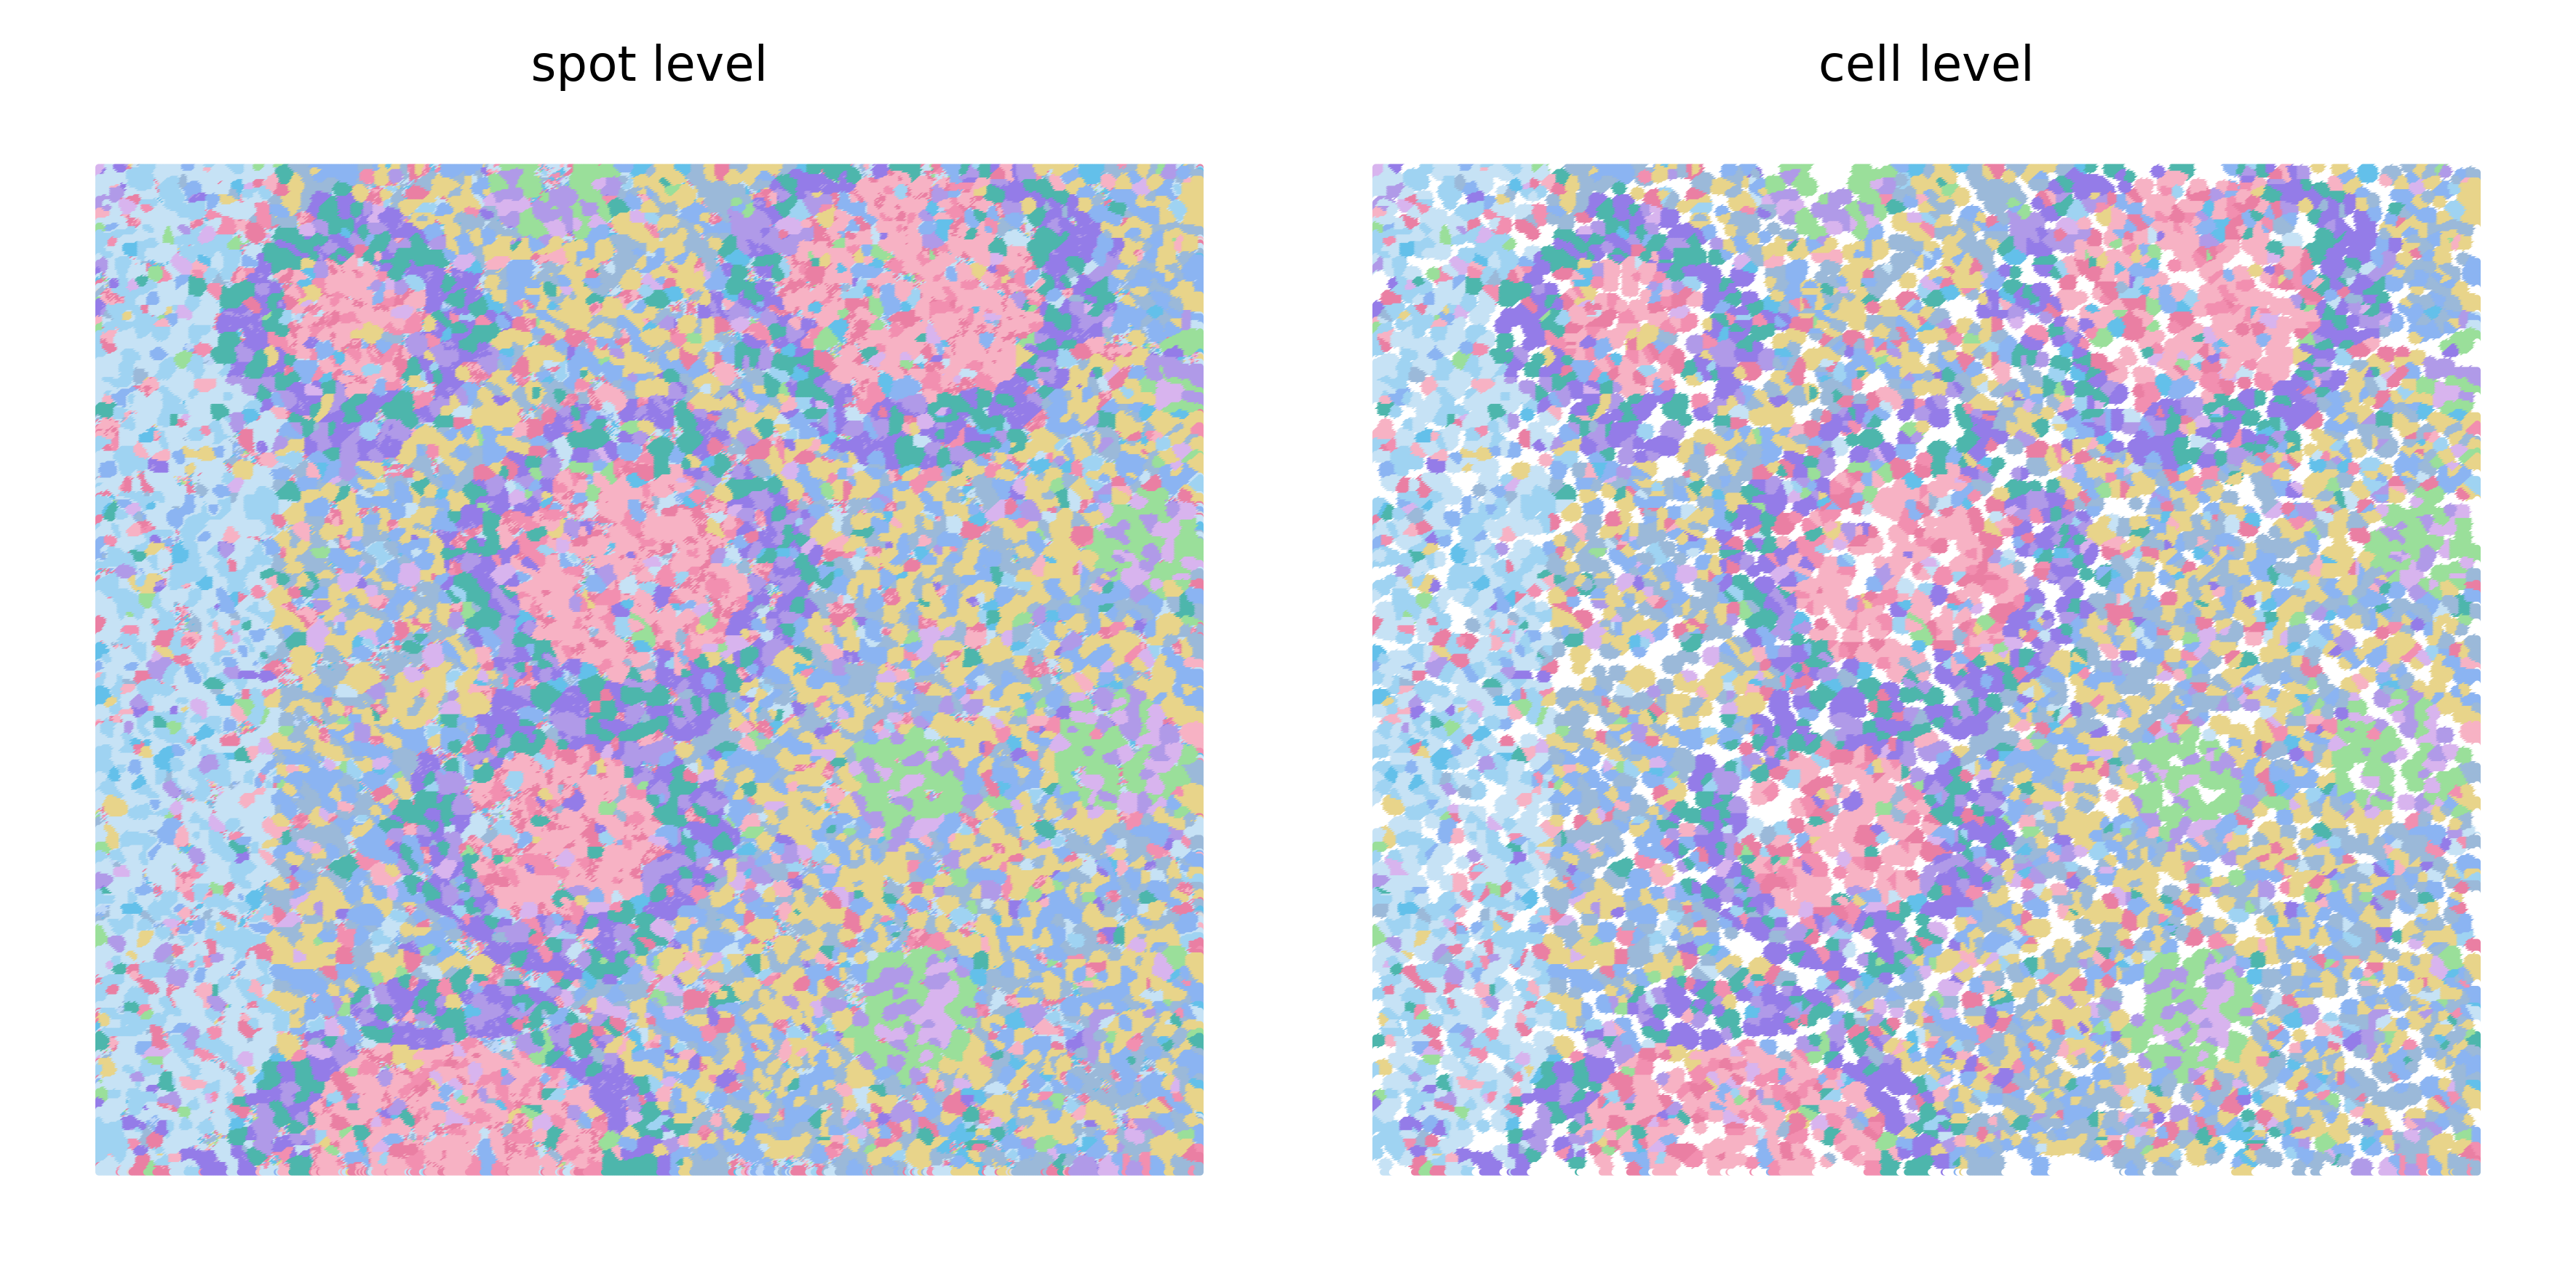

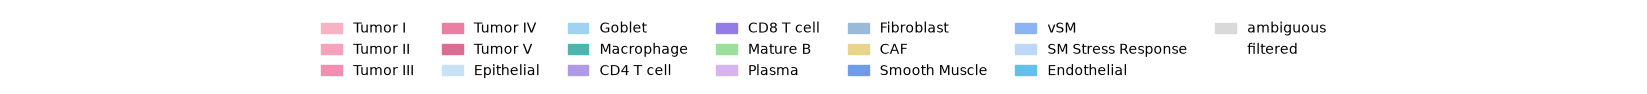

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3), dpi=600)

keys = ["spot", "cell"]
labels_all = {}
for i, ax in enumerate(axes):
    check = keys[i]
    x_raw, y_raw = adata.obsm["spatial_grid"][:, 0], adata.obsm["spatial_grid"][:, 1]

    # Cell-type probabilities
    prob = F.softmax(emb_all[check], dim=1)
    max_prob_raw, max_idx_raw = torch.max(prob, dim=1)

    if check == "cell":
        # Broadcast cell-level predictions back to their spots (spot -> cell mapping)
        S = S_s2c_all.coalesce()
        rows, cols = S.indices()[0], S.indices()[1]
        spot2target = torch.full((S.size(0),), -1, dtype=torch.long, device=S.device)
        spot2target[rows] = cols
        max_idx = torch.where(spot2target >= 0, max_idx_raw[spot2target], torch.tensor(-1, device=S.device))
        max_prob = torch.where(spot2target >= 0, max_prob_raw[spot2target], torch.tensor(0.0, device=S.device))
    else:
        max_prob, max_idx = max_prob_raw, max_idx_raw

    # --- Label assignment ---
    cell_labels = []
    for j in range(len(max_prob)):
        # max_idx == -1: the spot belongs to no valid cell
        if max_idx[j] == -1:
            cell_labels.append("filtered")
        elif max_prob[j] < 0.1:
            cell_labels.append("ambiguous")
        else:
            cell_labels.append(celltypes[max_idx[j]])
    labels_all[check] = cell_labels

    colors = [celltype_color[name] for name in cell_labels]
    ax.scatter(x_raw, y_raw, c=colors, s=5, marker='.', linewidths=0)
    ax.set_title(f"{check} level", fontsize=8)
    ax.invert_yaxis()
    ax.axis("off")

plt.tight_layout()
plt.savefig("spot_cell_type.png")
plt.show()

# Legend of all cell types in the color map
handles = [mpatches.Patch(color=color, label=label) for label, color in celltype_color.items()]
ncols = 7
nrows = (len(handles) + ncols - 1) // ncols
fig, ax = plt.subplots(figsize=(ncols * 3, nrows * 0.1))
ax.legend(handles=handles, loc='upper center', ncol=ncols, frameon=False, handlelength=1.5, fontsize=10)
ax.axis('off')
plt.tight_layout()
plt.show()

### 6.2 Cell-type accuracy against the ground truth

Each cell's ground-truth type is the majority `celltype` of its spots; the prediction is the argmax of the cell-level output.
Cells without ground truth (`NA`) or labeled `ambiguous` are excluded.

In [11]:
# --- Prediction: argmax cell type of each cell ---
pred_idx = F.softmax(emb_all["cell"], dim=1).argmax(1).cpu().numpy()
pred_ct  = np.asarray(celltypes)[pred_idx]

# --- Ground truth: spot cell type -> majority vote per cell ---
S = S_s2c_all.coalesce()
s_rows = S.indices()[0].cpu().numpy()
c_cols = S.indices()[1].cpu().numpy()
n_cell = S.size(1)
gt_spot = adata.obs["celltype"].astype(str).values
maj = pd.DataFrame({"cell": c_cols, "ct": gt_spot[s_rows]}).groupby("cell")["ct"].agg(lambda x: x.mode().iat[0])
gt_ct = np.array(["NA"] * n_cell, dtype=object)
gt_ct[maj.index.values] = maj.values
m = gt_ct != "NA"

# --- Evaluation label set: types present in the ground truth, excluding "ambiguous" ---
eval_labels = sorted(set(gt_ct[m]) - {"ambiguous"})
keep = m & np.isin(gt_ct, eval_labels)
print(f"evaluated cells: {int(keep.sum())}/{n_cell} (excluding NA and ambiguous)")

# Cells predicted as a type that does not exist in the ground truth (reported separately)
spurious = ~np.isin(pred_ct[keep], eval_labels)
print(f"cells predicted as a type absent from the ground truth: {spurious.sum()} ({spurious.mean():.2%}), "
      f"types: {sorted(set(pred_ct[keep][spurious]))}")

print("Accuracy     :", round(accuracy_score(gt_ct[keep], pred_ct[keep]), 4))
print("F1 (macro)   :", round(f1_score(gt_ct[keep], pred_ct[keep], labels=eval_labels,
                                       average="macro", zero_division=0), 4))
print("F1 (weighted):", round(f1_score(gt_ct[keep], pred_ct[keep], labels=eval_labels,
                                       average="weighted", zero_division=0), 4))
print()
print(classification_report(gt_ct[keep], pred_ct[keep], labels=eval_labels, zero_division=0))

evaluated cells: 8030/8030 (excluding NA and ambiguous)
cells predicted as a type absent from the ground truth: 0 (0.00%), types: []
Accuracy     : 0.8232
F1 (macro)   : 0.6835
F1 (weighted): 0.7871

                    precision    recall  f1-score   support

               CAF       0.96      1.00      0.98      1159
        CD4 T cell       0.88      1.00      0.94       424
        CD8 T cell       1.00      0.93      0.96       746
       Endothelial       0.99      0.99      0.99       145
        Epithelial       0.97      1.00      0.98       591
        Fibroblast       0.97      0.93      0.95      1078
            Goblet       1.00      1.00      1.00       465
        Macrophage       0.97      1.00      0.99       479
          Mature B       1.00      0.97      0.99       355
            Plasma       0.93      1.00      0.96       232
SM Stress Response       0.00      0.00      0.00       141
     Smooth Muscle       0.00      0.00      0.00       618
           Tumor I 

## 7. Niche detection

### 7.1 Niche clustering (UMAP + spatial map) and NMI / ARI

niche: 5 clusters
spots with a niche label: 320110 / 360000


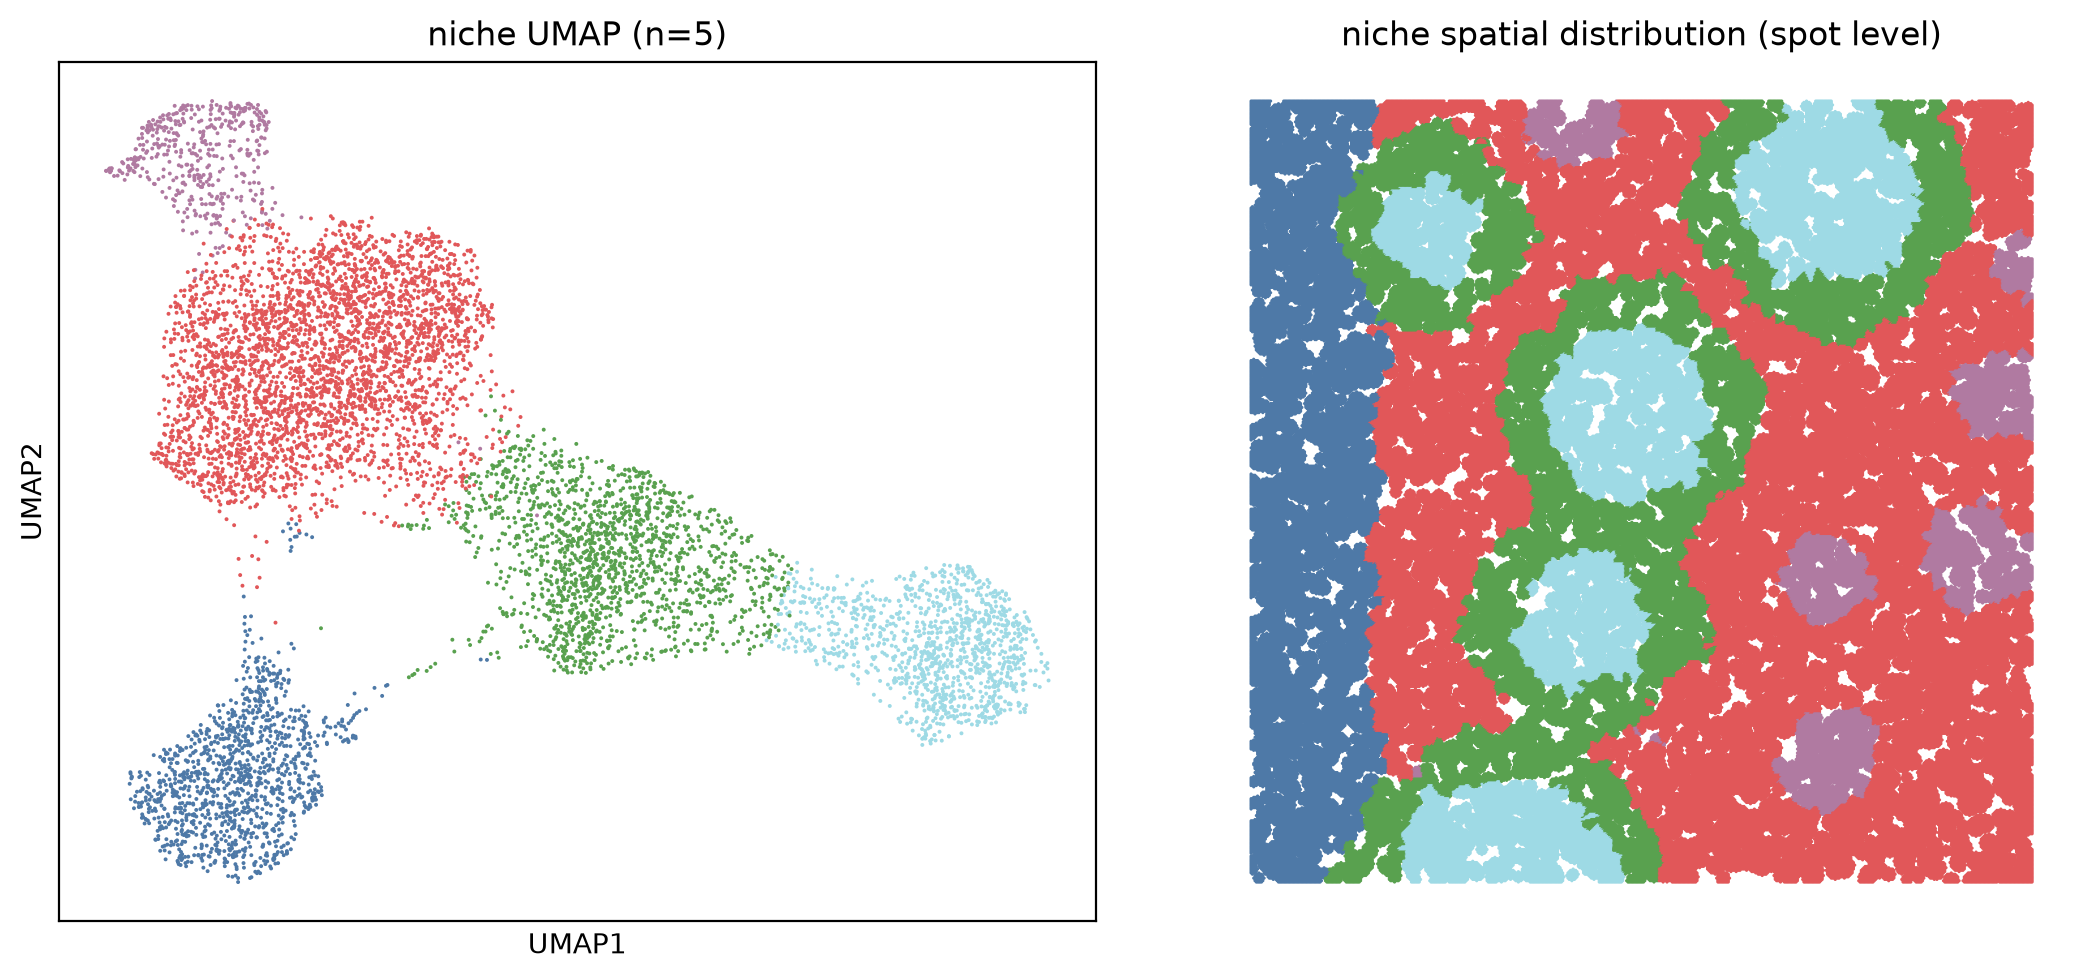

evaluated cells: 8030 / 8030
GT niches: 5,  pred niches: 5
NMI = 0.8463
ARI = 0.8809


In [12]:
torch.cuda.empty_cache()

# --- 1. Niche embedding: KMeans clustering + UMAP ---
X_niche = emb_all["niche"].numpy()
niche_label = KMeans(n_clusters=n_clusters, random_state=seed, n_init=20).fit_predict(X_niche)

adata_tmp = ad.AnnData(X_niche)
rsc.pp.neighbors(adata_tmp, use_rep='X', n_neighbors=emb_k)
rsc.tl.umap(adata_tmp, random_state=seed)
niche_umap = adata_tmp.obsm["X_umap"]

clusters_id = {"niche": niche_label}
print(f"niche: {len(np.unique(niche_label))} clusters")

# --- 2. Map niche clusters back to their center cells ---
S = S_s2c_all.coalesce()
rows, cols = S.indices()[0], S.indices()[1]
n_cell = S.size(1)

cell_niche = torch.full((n_cell,), -1, dtype=torch.long, device=S.device)
active = torch.as_tensor(active_niche_indices, device=S.device).long()
cell_niche[active] = torch.as_tensor(niche_label, device=S.device).long()

# --- 3. Broadcast to spots (each spot takes the niche of its cell) ---
spot2cell = torch.full((S.size(0),), -1, dtype=torch.long, device=S.device)
spot2cell[rows] = cols
spot_niche = torch.where(spot2cell >= 0,
                         cell_niche[spot2cell],
                         torch.tensor(-1, dtype=torch.long, device=S.device)).cpu().numpy()

xy = np.asarray(adata.obsm["spatial_grid"])
keep_spot = spot_niche >= 0
print(f"spots with a niche label: {keep_spot.sum()} / {len(xy)}")

# --- 4. Left: niche UMAP; right: spot-level niche spatial distribution ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=200)

axes[0].scatter(niche_umap[:, 0], niche_umap[:, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in niche_label], s=2, linewidths=0)
axes[0].set_title(f"niche UMAP (n={n_clusters})")
axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_xlabel("UMAP1"); axes[0].set_ylabel("UMAP2")

axes[1].scatter(xy[keep_spot, 0], xy[keep_spot, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in spot_niche[keep_spot]],
                s=5, marker='.', linewidths=0)
axes[1].set_title("niche spatial distribution (spot level)")
axes[1].invert_yaxis(); axes[1].set_aspect("equal"); axes[1].axis("off")

plt.tight_layout()
plt.show()

# ==================== NMI / ARI (cell-level evaluation) ====================
s_rows = S.indices()[0].cpu().numpy()
c_cols = S.indices()[1].cpu().numpy()

# --- Ground truth: spot niche -> majority vote per cell ---
gt_spot = pd.factorize(adata.obs["niche_id"].values)[0]          # integer labels
maj = pd.DataFrame({"cell": c_cols, "gt": gt_spot[s_rows]}).groupby("cell")["gt"].agg(lambda x: np.bincount(x).argmax())
gt_cell = np.full(n_cell, -1, dtype=np.int64)
gt_cell[maj.index.values] = maj.values

# --- Prediction: niche cluster of each cell ---
pred_cell = cell_niche.cpu().numpy()

mask = (pred_cell >= 0) & (gt_cell >= 0)
print(f"evaluated cells: {mask.sum()} / {n_cell}")
print(f"GT niches: {len(np.unique(gt_cell[mask]))},  pred niches: {len(np.unique(pred_cell[mask]))}")
print(f"NMI = {NMI(gt_cell[mask], pred_cell[mask]):.4f}")
print(f"ARI = {ARI(gt_cell[mask], pred_cell[mask]):.4f}")

### 7.2 Predicted cell-type composition of each niche cluster

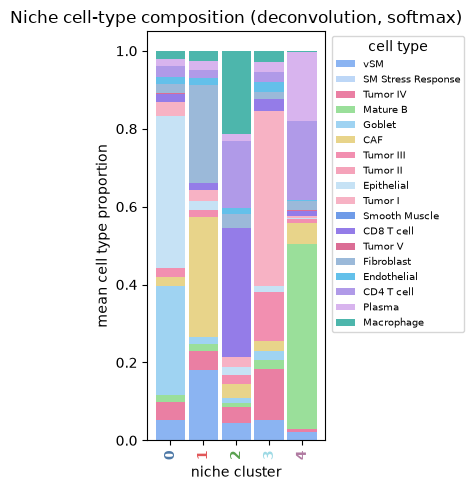

In [13]:
# --- Predicted cell-type proportions of each niche's center cell (softmax of the cell-level output) ---
prop = F.softmax(emb_all["cell"], dim=1).cpu().numpy()[np.asarray(active_niche_indices)]   # [n_niche, n_celltype]
prop_df = pd.DataFrame(prop, columns=celltypes)

# --- Mean composition per niche cluster, stacked bar chart ---
lab  = np.asarray(clusters_id["niche"])
comp = prop_df.groupby(lab).mean()                           # [n_cluster, n_celltype]

ax = comp.plot(kind="bar", stacked=True, figsize=(1 + 0.6*len(comp), 5),
               color=[celltype_color[c] for c in comp.columns], width=0.9)
for tick, cid in zip(ax.get_xticklabels(), comp.index):      # color x tick labels by niche cluster
    tick.set_color(umap_color[f"Cluster_{cid % 40}"]); tick.set_fontweight("bold")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7,
          title="cell type", ncol=1 + len(celltypes)//20)
ax.set_xlabel("niche cluster"); ax.set_ylabel("mean cell type proportion")
ax.set_title("Niche cell-type composition (deconvolution, softmax)")
plt.tight_layout(); plt.show()